# Week 4: Logistic Regression and Feature Scaling

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay
)

sns.set_theme(style="whitegrid")

In [ ]:
df1 = pd.read_csv("digital_marketing_campaign_dataset.csv")
df2 = pd.read_csv("marketing_and_product_performance.csv")
df3 = pd.read_csv("companies_clean_734.csv")

print("Digital Marketing Campaign:", df1.shape)
print("Marketing and Product Performance:", df2.shape)
print("Synthetic B2B CRM & Marketing Dataset:", df3.shape)

Digital Marketing Campaign: (8000, 20)
Marketing and Product Performance: (10000, 17)
Companies: (734, 19)


## Dataset 1: Digital Marketing Campaign

The binary target variable is Conversion, representing whether a customer converted. Logistic regression will be used to examine whether the selected marketing variables can classify customers based on conversion outcome. The predictors are AdSpend, ClickThroughRate, WebsiteVisits, TimeOnSite, and EmailClicks. Models will first be evaluated without feature scaling and then with standardized predictors.

In [5]:
df1["Conversion"].value_counts()
df1["Conversion"].value_counts(normalize=True).round(4)

Conversion
1    0.8765
0    0.1235
Name: proportion, dtype: float64

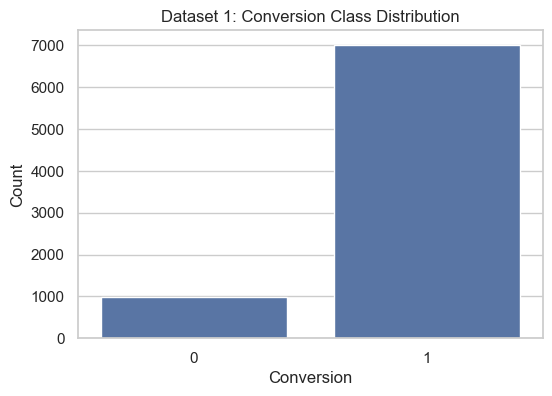

In [6]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df1, x="Conversion")
plt.xlabel("Conversion")
plt.ylabel("Count")
plt.title("Dataset 1: Conversion Class Distribution")
plt.show()

### Class Distribution Findings

The Conversion target is imbalanced, with 87.65% of observations classified as conversions and 12.35% classified as non-conversions. The majority of observations belong to the conversion class, accuracy alone may provide a misleading measure of model performance. Precision, recall, F1 score, ROC-AUC, and the confusion matrix will also be evaluated to better understand the model's classification performance.

In [7]:
features1 = ["AdSpend", "ClickThroughRate", "WebsiteVisits", "TimeOnSite", "EmailClicks"]

X1 = df1[features1]
y1 = df1["Conversion"]

X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.2, random_state=42, stratify=y1)

logistic1 = LogisticRegression(max_iter=1000)
logistic1.fit(X1_train, y1_train)

pred1 = logistic1.predict(X1_test)
prob1 = logistic1.predict_proba(X1_test)[:, 1]

print("Accuracy:", round(accuracy_score(y1_test, pred1), 4))
print("Precision:", round(precision_score(y1_test, pred1), 4))
print("Recall:", round(recall_score(y1_test, pred1), 4))
print("F1 Score:", round(f1_score(y1_test, pred1), 4))
print("ROC-AUC:", round(roc_auc_score(y1_test, prob1), 4))

Accuracy: 0.8762
Precision: 0.8772
Recall: 0.9986
F1 Score: 0.934
ROC-AUC: 0.7056


### Unscaled Logistic Regression Findings

The unscaled logistic regression model achieved an accuracy of 87.62%, precision of 87.72%, recall of 99.86%, and an F1 score of 0.9340. The model also achieved a ROC-AUC score of 0.7056. While the level of accuracy and recall is quite high, there is an imbalance in the dataset as it is dominated by conversions. It is thus important to consider these two metrics along with the confusion matrix.

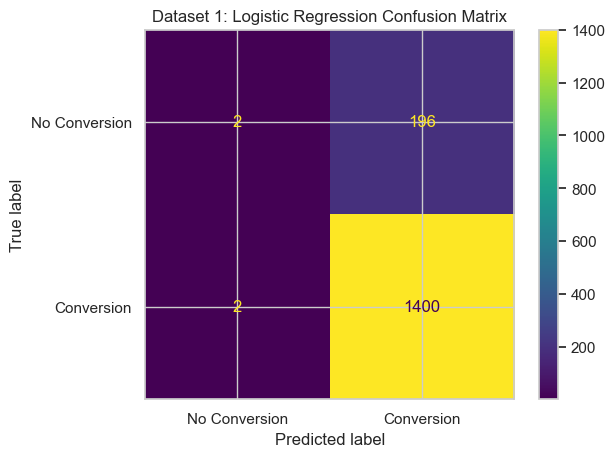

[[   2  196]
 [   2 1400]]


In [8]:
cm1 = confusion_matrix(y1_test, pred1)
disp = ConfusionMatrixDisplay(confusion_matrix=cm1, display_labels=["No Conversion", "Conversion"])
disp.plot()
plt.title("Dataset 1: Logistic Regression Confusion Matrix")
plt.show()
print(cm1)

### Confusion Matrix Findings

The confusion matrix shows that the model correctly classified 1,400 conversions but only 2 non-conversions. It incorrectly classified 196 non-conversions as conversions and missed only 2 actual conversions. This explains the model's high recall and accuracy. Conversions make up most of the dataset, the model predicts nearly every observation as a conversion. Therefore, the high accuracy does not mean the model performs equally well across both classes.

In [9]:
scaled_logistic1 = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000))
])

scaled_logistic1.fit(X1_train, y1_train)

scaled_pred1 = scaled_logistic1.predict(X1_test)
scaled_prob1 = scaled_logistic1.predict_proba(X1_test)[:, 1]

print("Accuracy:", round(accuracy_score(y1_test, scaled_pred1), 4))
print("Precision:", round(precision_score(y1_test, scaled_pred1), 4))
print("Recall:", round(recall_score(y1_test, scaled_pred1), 4))
print("F1 Score:", round(f1_score(y1_test, scaled_pred1), 4))
print("ROC-AUC:", round(roc_auc_score(y1_test, scaled_prob1), 4))

Accuracy: 0.8762
Precision: 0.8772
Recall: 0.9986
F1 Score: 0.934
ROC-AUC: 0.7044


### Feature Scaling Findings

The results for feature scaling were almost the same as those of the logistic regression without scaling. The accuracy is still at 87.62%, the precision is still at 87.72%, the recall is still at 99.86%, and the F1 score is still at 0.9340. The ROC-AUC went down to 0.7044 from 0.7056.

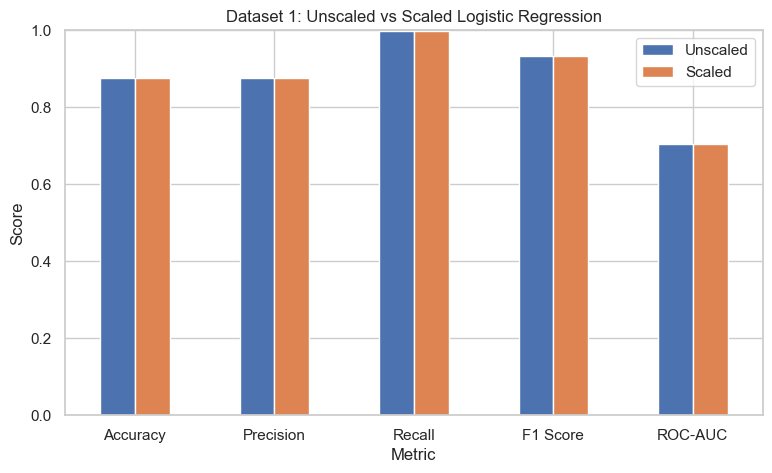

In [10]:
comparison1 = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "Unscaled": [accuracy_score(y1_test, pred1), precision_score(y1_test, pred1), recall_score(y1_test, pred1), f1_score(y1_test, pred1), roc_auc_score(y1_test, prob1)],
    "Scaled": [accuracy_score(y1_test, scaled_pred1), precision_score(y1_test, scaled_pred1), recall_score(y1_test, scaled_pred1), f1_score(y1_test, scaled_pred1), roc_auc_score(y1_test, scaled_prob1)]
})

comparison1.set_index("Metric").plot(kind="bar", figsize=(9, 5))
plt.ylabel("Score")
plt.title("Dataset 1: Unscaled vs Scaled Logistic Regression")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

<Figure size 700x500 with 0 Axes>

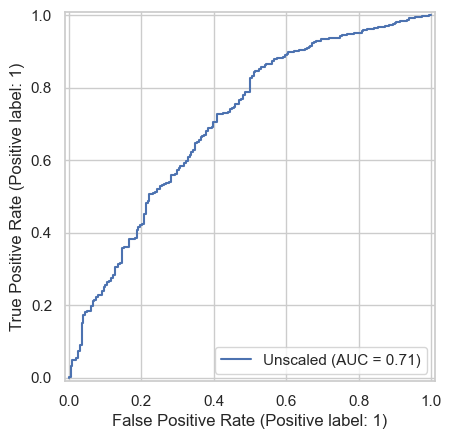

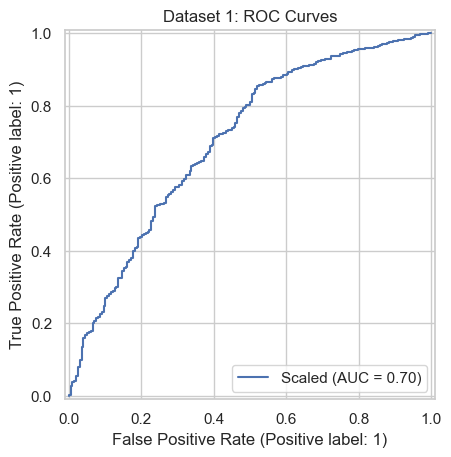

In [11]:
plt.figure(figsize=(7, 5))
RocCurveDisplay.from_predictions(y1_test, prob1, name="Unscaled")
RocCurveDisplay.from_predictions(y1_test, scaled_prob1, name="Scaled")
plt.title("Dataset 1: ROC Curves")
plt.show()

### Training vs. Testing Performance

Training and holdout testing performance were compared to evaluate whether the logistic regression model showed signs of overfitting. Accuracy, F1 score, and ROC-AUC were used to compare performance on the two datasets.

     Metric  Training  Testing
0  Accuracy    0.8789   0.8762
1  F1 Score    0.9353   0.9340
2   ROC-AUC    0.7298   0.7044


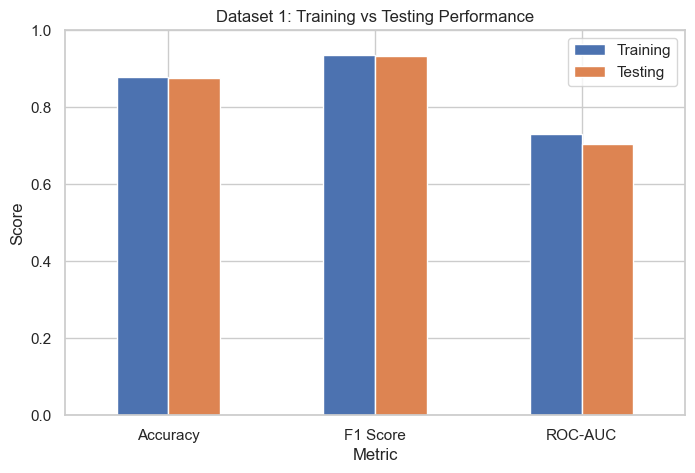

In [12]:
train_pred1 = scaled_logistic1.predict(X1_train)
train_prob1 = scaled_logistic1.predict_proba(X1_train)[:, 1]

performance1 = pd.DataFrame({
    "Metric": ["Accuracy", "F1 Score", "ROC-AUC"],
    "Training": [accuracy_score(y1_train, train_pred1), f1_score(y1_train, train_pred1), roc_auc_score(y1_train, train_prob1)],
    "Testing": [accuracy_score(y1_test, scaled_pred1), f1_score(y1_test, scaled_pred1), roc_auc_score(y1_test, scaled_prob1)]
})

print(performance1.round(4))

performance1.set_index("Metric").plot(kind="bar", figsize=(8, 5))
plt.ylabel("Score")
plt.title("Dataset 1: Training vs Testing Performance")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

### Training vs. Testing Findings

The scaled logistic regression model produced similar results across the training and testing datasets. Training accuracy was 87.89%, compared with 87.62% on the testing set. The F1 scores were also nearly identical at 0.9353 and 0.9340.

ROC-AUC decreased from 0.7298 during training to 0.7044 during testing. Although this indicates a small reduction in performance on unseen data, there is no strong evidence of overfitting. However, the high accuracy and F1 scores remain influenced by the dataset's class imbalance.

### Hyperparameter Optimization

GridSearchCV was used with five-fold cross-validation to optimize the logistic regression model. Different regularization strengths and class weights were evaluated to determine whether tuning could improve classification performance.

ROC-AUC was used as the optimization metric because the target variable is imbalanced. The holdout testing set was reserved for evaluating the final tuned model.

In [28]:
from sklearn.model_selection import GridSearchCV

param_grid1 = {
    "logistic__C": [0.01, 0.1, 1, 10, 100],
    "logistic__class_weight": [None, "balanced"]
}

grid1 = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("logistic", LogisticRegression(max_iter=1000))]),
    param_grid1, cv=5, scoring="roc_auc", n_jobs=-1
)

grid1.fit(X1_train, y1_train)

print("Best Parameters:", grid1.best_params_)
print("Best Cross-Validation ROC-AUC:", round(grid1.best_score_, 4))

Best Parameters: {'logistic__C': 0.01, 'logistic__class_weight': 'balanced'}
Best Cross-Validation ROC-AUC: 0.7275


### Hyperparameter Tuning Findings

GridSearchCV selected a regularization strength of C = 0.01 and balanced class weights. The best model achieved a cross-validation ROC-AUC of 0.7275.

The balanced class weights may help address the class imbalance by giving more importance to non-conversions. The tuned model will be evaluated on the holdout testing set to determine whether these settings improve classification performance.

In [30]:
tuned_logistic1 = grid1.best_estimator_
tuned_pred1 = tuned_logistic1.predict(X1_test)
tuned_prob1 = tuned_logistic1.predict_proba(X1_test)[:, 1]

print("Accuracy:", round(accuracy_score(y1_test, tuned_pred1), 4))
print("Precision:", round(precision_score(y1_test, tuned_pred1), 4))
print("Recall:", round(recall_score(y1_test, tuned_pred1), 4))
print("F1 Score:", round(f1_score(y1_test, tuned_pred1), 4))
print("ROC-AUC:", round(roc_auc_score(y1_test, tuned_prob1), 4))

Accuracy: 0.6575
Precision: 0.9261
Recall: 0.6619
F1 Score: 0.772
ROC-AUC: 0.7043


### Tuned Model Findings

The tuned logistic regression model achieved an accuracy of 65.75%, precision of 92.61%, recall of 66.19%, and an F1 score of 0.7720. ROC-AUC remained approximately unchanged at 0.7043.

Compared with the original scaled model, tuning increased precision but decreased accuracy, recall, and F1 score. This suggests that balancing the class weights changed the model's classification behavior rather than improving its overall ability to distinguish between conversions and non-conversions.

Original Model:
[[   2  196]
 [   2 1400]]

Tuned Model:
[[124  74]
 [474 928]]


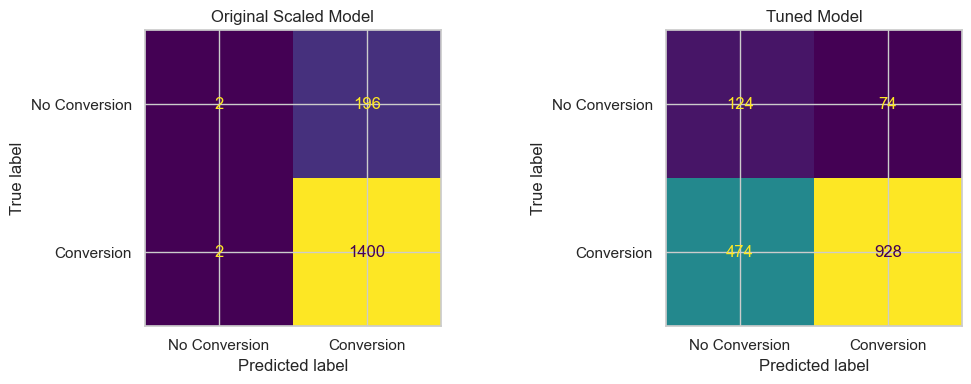

In [31]:
print("Original Model:")
print(confusion_matrix(y1_test, scaled_pred1))

print("\nTuned Model:")
print(confusion_matrix(y1_test, tuned_pred1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(y1_test, scaled_pred1, display_labels=["No Conversion", "Conversion"], ax=axes[0], colorbar=False)
axes[0].set_title("Original Scaled Model")

ConfusionMatrixDisplay.from_predictions(y1_test, tuned_pred1, display_labels=["No Conversion", "Conversion"], ax=axes[1], colorbar=False)
axes[1].set_title("Tuned Model")

plt.tight_layout()
plt.show()

### Hyperparameter Optimization Comparison

Hyperparameter tuning significantly improved the model's ability to identify non-conversions. The original model correctly identified only 2 of 198 non-conversions, while the tuned model correctly identified 124.

However, this improvement came at the expense of conversion classification. The tuned model correctly identified 928 conversions compared with 1,400 for the original model.

Overall, balanced class weights helped address the model's bias toward the majority class, but accuracy decreased and ROC-AUC remained nearly unchanged. This demonstrates the tradeoff between identifying minority-class observations and maintaining overall classification accuracy.

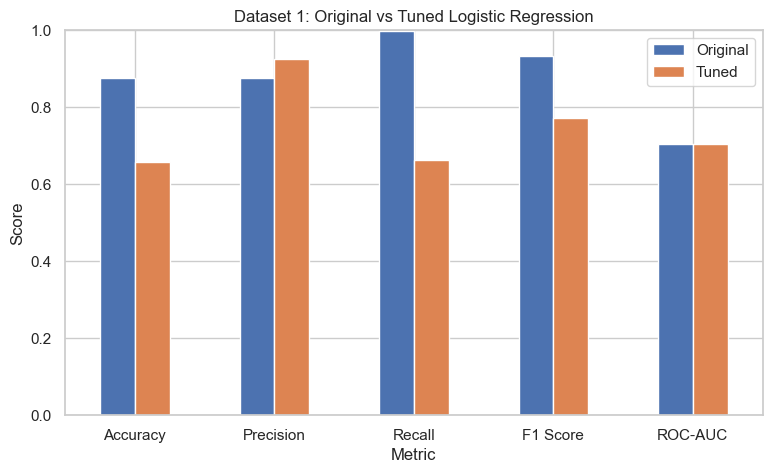

In [32]:
comparison_tuned1 = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "Original": [accuracy_score(y1_test, scaled_pred1), precision_score(y1_test, scaled_pred1), recall_score(y1_test, scaled_pred1), f1_score(y1_test, scaled_pred1), roc_auc_score(y1_test, scaled_prob1)],
    "Tuned": [accuracy_score(y1_test, tuned_pred1), precision_score(y1_test, tuned_pred1), recall_score(y1_test, tuned_pred1), f1_score(y1_test, tuned_pred1), roc_auc_score(y1_test, tuned_prob1)]
})

comparison_tuned1.set_index("Metric").plot(kind="bar", figsize=(9, 5))
plt.ylabel("Score")
plt.title("Dataset 1: Original vs Tuned Logistic Regression")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

### Dataset 1 Conclusion

Logistic regression achieved 87.62% testing accuracy, but the confusion matrix revealed that the original model primarily predicted the majority conversion class. Feature scaling produced almost identical results. Training and testing performance were similar, suggesting little evidence of overfitting. Hyperparameter optimization using GridSearchCV selected C = 0.01 and balanced class weights, achieving a cross-validation ROC-AUC of 0.7275. The tuned model improved the identification of non-conversions from 2 to 124 out of 198 observations. However, testing accuracy decreased to 65.75%, and ROC-AUC remained approximately 0.70. Overall, tuning improved minority-class identification but introduced a tradeoff in conversion recall and overall accuracy.

## Dataset 2: Marketing and Product Performance

Dataset 2 does not contain a predefined binary target, so a classification target was created using ROI. Campaigns with ROI above the median are classified as high ROI, while campaigns at or below the median are classified as low ROI. Logistic regression and feature scaling are used to evaluate whether campaign and sales variables can distinguish between high- and low-ROI campaigns.

In [13]:
roi_median = df2["ROI"].median()
df2["High_ROI"] = (df2["ROI"] > roi_median).astype(int)
print("Median ROI:", roi_median)
print(df2["High_ROI"].value_counts())
print(df2["High_ROI"].value_counts(normalize=True).round(4))

Median ROI: 2.75
High_ROI
0    5002
1    4998
Name: count, dtype: int64
High_ROI
0    0.5002
1    0.4998
Name: proportion, dtype: float64


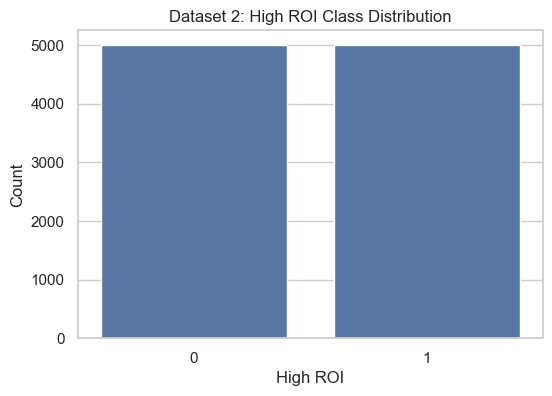

In [14]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df2, x="High_ROI")
plt.xlabel("High ROI")
plt.ylabel("Count")
plt.title("Dataset 2: High ROI Class Distribution")
plt.show()

### Class Distribution Findings

The median ROI is 2.75. Using this value to create the classification target resulted in an almost perfectly balanced dataset, with 50.02% of campaigns classified as low ROI and 49.98% classified as high ROI. This balanced distribution allows the logistic regression model to be evaluated without the severe class imbalance observed in Dataset 1.

In [15]:
features2 = ["Clicks", "Conversions", "Units_Sold", "Bundle_Price", "Discount_Level"]

X2 = df2[features2]
y2 = df2["High_ROI"]

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42, stratify=y2)

logistic2 = LogisticRegression(max_iter=1000)
logistic2.fit(X2_train, y2_train)

pred2 = logistic2.predict(X2_test)
prob2 = logistic2.predict_proba(X2_test)[:, 1]

print("Accuracy:", round(accuracy_score(y2_test, pred2), 4))
print("Precision:", round(precision_score(y2_test, pred2), 4))
print("Recall:", round(recall_score(y2_test, pred2), 4))
print("F1 Score:", round(f1_score(y2_test, pred2), 4))
print("ROC-AUC:", round(roc_auc_score(y2_test, prob2), 4))

Accuracy: 0.501
Precision: 0.501
Recall: 0.498
F1 Score: 0.4995
ROC-AUC: 0.4981


### Unscaled Logistic Regression Findings

The unscaled logistic regression model achieved an accuracy of 50.10%, precision of 50.10%, recall of 49.80%, and an F1 score of 0.4995. The ROC-AUC score was 0.4981. Since there is almost an equal proportion among the two classes, a performance score close to 50% implies that the algorithm is working at the level of chance. Consequently, the selected attributes have limited discriminative power.

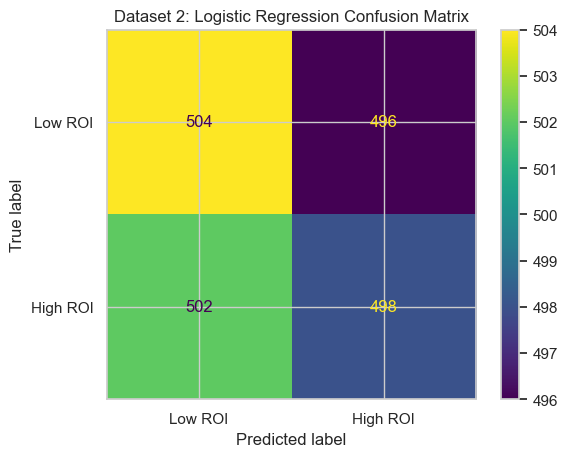

[[504 496]
 [502 498]]


In [16]:
cm2 = confusion_matrix(y2_test, pred2)
disp = ConfusionMatrixDisplay(confusion_matrix=cm2, display_labels=["Low ROI", "High ROI"])
disp.plot()
plt.title("Dataset 2: Logistic Regression Confusion Matrix")
plt.show()
print(cm2)

### Confusion Matrix Findings

The confusion matrix shows that the model classified both ROI groups at approximately equal rates. It correctly identified 504 low-ROI campaigns and 498 high-ROI campaigns, while misclassifying 496 low-ROI campaigns and 502 high-ROI campaigns. The nearly even distribution of correct and incorrect predictions supports the earlier finding that the model is performing close to chance level.

In [17]:
scaled_logistic2 = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000))
])

scaled_logistic2.fit(X2_train, y2_train)

scaled_pred2 = scaled_logistic2.predict(X2_test)
scaled_prob2 = scaled_logistic2.predict_proba(X2_test)[:, 1]

print("Accuracy:", round(accuracy_score(y2_test, scaled_pred2), 4))
print("Precision:", round(precision_score(y2_test, scaled_pred2), 4))
print("Recall:", round(recall_score(y2_test, scaled_pred2), 4))
print("F1 Score:", round(f1_score(y2_test, scaled_pred2), 4))
print("ROC-AUC:", round(roc_auc_score(y2_test, scaled_prob2), 4))

Accuracy: 0.501
Precision: 0.501
Recall: 0.498
F1 Score: 0.4995
ROC-AUC: 0.4981


### Feature Scaling Findings

Feature scaling produced the same classification results as the unscaled logistic regression model. Accuracy remained 50.10%, precision remained 50.10%, recall remained 49.80%, and the F1 score remained 0.4995. ROC-AUC also remained unchanged at 0.4981. These results indicate that standardizing the predictors did not improve the model's ability to distinguish between high- and low-ROI campaigns.

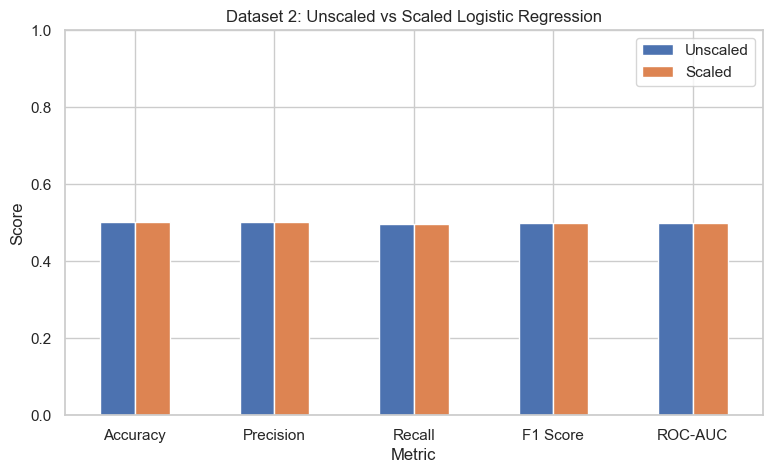

In [18]:
comparison2 = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "Unscaled": [accuracy_score(y2_test, pred2), precision_score(y2_test, pred2), recall_score(y2_test, pred2), f1_score(y2_test, pred2), roc_auc_score(y2_test, prob2)],
    "Scaled": [accuracy_score(y2_test, scaled_pred2), precision_score(y2_test, scaled_pred2), recall_score(y2_test, scaled_pred2), f1_score(y2_test, scaled_pred2), roc_auc_score(y2_test, scaled_prob2)]
})

comparison2.set_index("Metric").plot(kind="bar", figsize=(9, 5))
plt.ylabel("Score")
plt.title("Dataset 2: Unscaled vs Scaled Logistic Regression")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

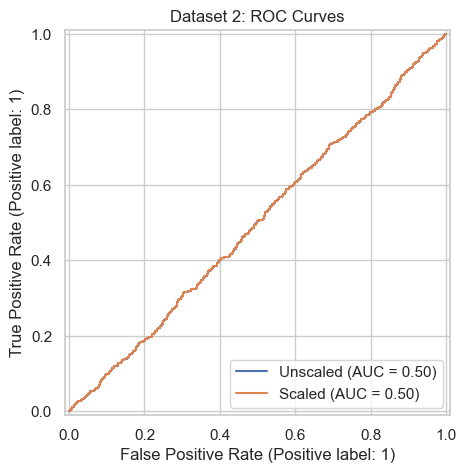

In [19]:
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(y2_test, prob2, name="Unscaled", ax=ax)
RocCurveDisplay.from_predictions(y2_test, scaled_prob2, name="Scaled", ax=ax)
plt.title("Dataset 2: ROC Curves")
plt.show()

### Training vs. Testing Performance

Training and holdout testing performance were compared to evaluate potential overfitting. Accuracy, F1 score, and ROC-AUC were used to determine whether the logistic regression model performed consistently on unseen data.

     Metric  Training  Testing
0  Accuracy    0.5134   0.5010
1  F1 Score    0.5094   0.4995
2   ROC-AUC    0.5161   0.4981


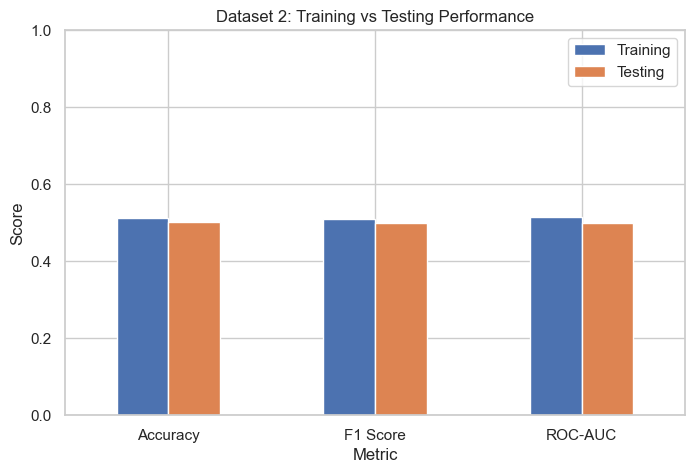

In [33]:
train_pred2 = scaled_logistic2.predict(X2_train)
train_prob2 = scaled_logistic2.predict_proba(X2_train)[:, 1]

performance2 = pd.DataFrame({
    "Metric": ["Accuracy", "F1 Score", "ROC-AUC"],
    "Training": [accuracy_score(y2_train, train_pred2), f1_score(y2_train, train_pred2), roc_auc_score(y2_train, train_prob2)],
    "Testing": [accuracy_score(y2_test, scaled_pred2), f1_score(y2_test, scaled_pred2), roc_auc_score(y2_test, scaled_prob2)]
})

print(performance2.round(4))

performance2.set_index("Metric").plot(kind="bar", figsize=(8, 5))
plt.ylabel("Score")
plt.title("Dataset 2: Training vs Testing Performance")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

### Training vs. Testing Findings

The scaled logistic regression model produced similar training and testing results. Training accuracy was 51.34%, compared with 50.10% on the testing set. The F1 score decreased slightly from 0.5094 to 0.4995, while ROC-AUC decreased from 0.5161 to 0.4981. These small differences suggest little evidence of overfitting. However, performance remained close to chance level on both datasets, indicating that the selected predictors provide limited ability to classify campaigns as high or low ROI.

### Hyperparameter Optimization

GridSearchCV was used with five-fold cross-validation to test different regularization strengths and class weights. Accuracy was selected as the optimization metric because the high- and low-ROI classes are nearly balanced. The best model was selected using the training data, while the holdout testing set was reserved for evaluating its performance on unseen observations.

In [34]:
param_grid2 = {
    "logistic__C": [0.01, 0.1, 1, 10, 100],
    "logistic__class_weight": [None, "balanced"]
}

grid2 = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("logistic", LogisticRegression(max_iter=1000))]),
    param_grid2, cv=5, scoring="accuracy", n_jobs=-1
)

grid2.fit(X2_train, y2_train)

print("Best Parameters:", grid2.best_params_)
print("Best Cross-Validation Accuracy:", round(grid2.best_score_, 4))

Best Parameters: {'logistic__C': 0.01, 'logistic__class_weight': None}
Best Cross-Validation Accuracy: 0.5058


GridSearchCV selected a regularization strength of C = 0.01 without balanced class weights. The best model achieved a five-fold cross-validation accuracy of 50.58%. Although hyperparameter optimization identified the best settings among those tested, the cross-validation accuracy remained close to 50%, suggesting that the selected predictors have limited ability to distinguish between high- and low-ROI campaigns.

In [36]:
tuned_logistic2 = grid2.best_estimator_
tuned_pred2 = tuned_logistic2.predict(X2_test)
tuned_prob2 = tuned_logistic2.predict_proba(X2_test)[:, 1]

print("Accuracy:", round(accuracy_score(y2_test, tuned_pred2), 4))
print("Precision:", round(precision_score(y2_test, tuned_pred2), 4))
print("Recall:", round(recall_score(y2_test, tuned_pred2), 4))
print("F1 Score:", round(f1_score(y2_test, tuned_pred2), 4))
print("ROC-AUC:", round(roc_auc_score(y2_test, tuned_prob2), 4))

Accuracy: 0.5015
Precision: 0.5015
Recall: 0.498
F1 Score: 0.4997
ROC-AUC: 0.4981


The tuned logistic regression model achieved an accuracy of 50.15%, precision of 50.15%, recall of 49.80%, and an F1 score of 0.4997. ROC-AUC remained unchanged at 0.4981. Compared with the original scaled model, hyperparameter tuning produced only a negligible improvement in accuracy, precision, and F1 score. Overall, the selected predictors continued to provide limited ability to distinguish between high- and low-ROI campaigns.

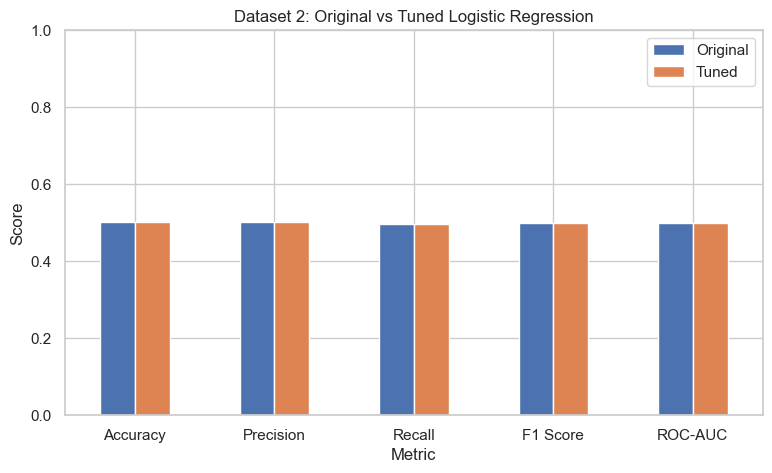

In [37]:
comparison_tuned2 = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "Original": [accuracy_score(y2_test, scaled_pred2), precision_score(y2_test, scaled_pred2), recall_score(y2_test, scaled_pred2), f1_score(y2_test, scaled_pred2), roc_auc_score(y2_test, scaled_prob2)],
    "Tuned": [accuracy_score(y2_test, tuned_pred2), precision_score(y2_test, tuned_pred2), recall_score(y2_test, tuned_pred2), f1_score(y2_test, tuned_pred2), roc_auc_score(y2_test, tuned_prob2)]
})

comparison_tuned2.set_index("Metric").plot(kind="bar", figsize=(9, 5))
plt.ylabel("Score")
plt.title("Dataset 2: Original vs Tuned Logistic Regression")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

### Dataset 2 Conclusion

The logistic regression algorithm had similar performance close to random guessing in the classification of high and low ROI campaigns. The model attained a testing accuracy of 50.10% and an AUC value of 0.4981. Feature scaling didn’t have any significant effect on improving performance. The training and testing performance were almost equal, implying that there was no overfitting. Through GridSearchCV for hyperparameter tuning, the optimum value of C parameter was determined to be 0.01 without class weights resulting in an accuracy of 50.58%.

## Dataset 3: Synthetic B2B CRM & Marketing Dataset

For Dataset 3, Contract_Status will be examined as the classification target. Logistic regression and feature scaling will be used to evaluate whether company characteristics and purchasing behavior can help classify contract status.

In [20]:
print(df3["Contract_Status"].value_counts())
print(df3["Contract_Status"].value_counts(normalize=True).round(4))

Contract_Status
Active     528
Pending    135
Expired     71
Name: count, dtype: int64
Contract_Status
Active     0.7193
Pending    0.1839
Expired    0.0967
Name: proportion, dtype: float64


### Class Distribution Findings

Contract_Status contains three categories: Active, Pending, and Expired. Active contracts represent 71.93% of the dataset, while Pending contracts represent 18.39% and Expired contracts represent 9.67%. For logistic regression, the target will be simplified into a binary outcome that distinguishes active contracts from contracts that are not currently active.

In [21]:
df3["Active_Contract"] = (df3["Contract_Status"] == "Active").astype(int)
print(df3["Active_Contract"].value_counts())
print(df3["Active_Contract"].value_counts(normalize=True).round(4))

Active_Contract
1    528
0    206
Name: count, dtype: int64
Active_Contract
1    0.7193
0    0.2807
Name: proportion, dtype: float64


### Binary Target Findings

After combining Pending and Expired contracts into a Not Active category, 71.93% of companies have active contracts and 28.07% have contracts that are not active. The target is moderately imbalanced toward active contracts, so classification performance will be evaluated using multiple metrics rather than accuracy alone.

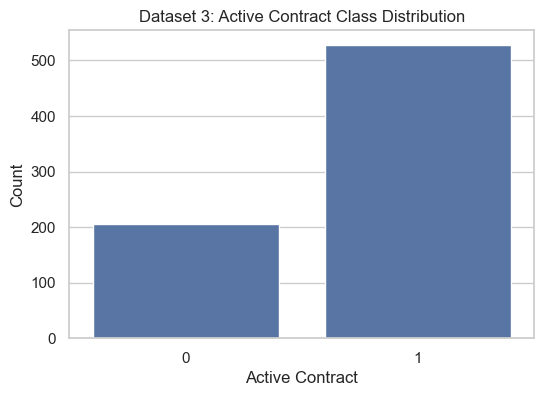

In [22]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df3, x="Active_Contract")
plt.xlabel("Active Contract")
plt.ylabel("Count")
plt.title("Dataset 3: Active Contract Class Distribution")
plt.show()

In [23]:
features3 = ["Annual_Revenue (M₺)", "Marketing_Spend (K₺)", "Days_Since_Last_Purchase", "Total_Purchases_Last_Year"]

X3 = df3[features3]
y3 = df3["Active_Contract"]

X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y3, test_size=0.2, random_state=42, stratify=y3)

logistic3 = LogisticRegression(max_iter=1000)
logistic3.fit(X3_train, y3_train)

pred3 = logistic3.predict(X3_test)
prob3 = logistic3.predict_proba(X3_test)[:, 1]

print("Accuracy:", round(accuracy_score(y3_test, pred3), 4))
print("Precision:", round(precision_score(y3_test, pred3), 4))
print("Recall:", round(recall_score(y3_test, pred3), 4))
print("F1 Score:", round(f1_score(y3_test, pred3), 4))
print("ROC-AUC:", round(roc_auc_score(y3_test, prob3), 4))

Accuracy: 0.7211
Precision: 0.7211
Recall: 1.0
F1 Score: 0.8379
ROC-AUC: 0.5186


### Unscaled Logistic Regression Findings

The unscaled logistic regression model achieved an accuracy of 72.11%, precision of 72.11%, recall of 100%, and an F1 score of 0.8379. The ROC-AUC score was 0.5186. Although accuracy appears relatively high, 71.93% of the dataset belongs to the Active class. The 100% recall suggests that the model may be predicting nearly every observation as Active. The ROC-AUC score also indicates weak ability to distinguish between Active and Not Active contracts.

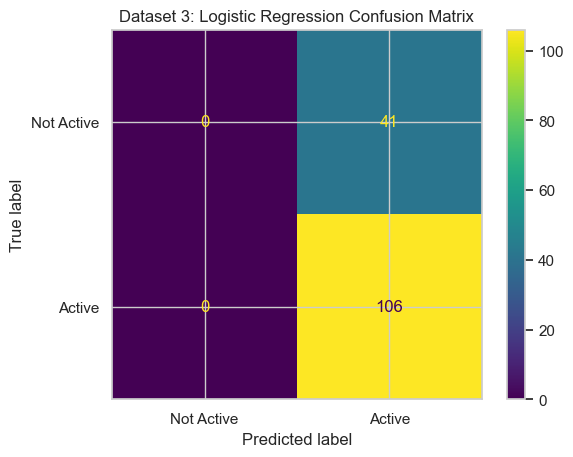

[[  0  41]
 [  0 106]]


In [24]:
cm3 = confusion_matrix(y3_test, pred3)
disp = ConfusionMatrixDisplay(confusion_matrix=cm3, display_labels=["Not Active", "Active"])
disp.plot()
plt.title("Dataset 3: Logistic Regression Confusion Matrix")
plt.show()
print(cm3)

The confusion matrix confirms that the model classified every observation as Active. It correctly classified all 106 active contracts but incorrectly classified all 41 not-active contracts as Active. This explains the 100% recall and relatively high accuracy. The model is strongly influenced by the majority class and is not successfully distinguishing between Active and Not Active contracts.

In [25]:
scaled_logistic3 = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000))
])

scaled_logistic3.fit(X3_train, y3_train)

scaled_pred3 = scaled_logistic3.predict(X3_test)
scaled_prob3 = scaled_logistic3.predict_proba(X3_test)[:, 1]

print("Accuracy:", round(accuracy_score(y3_test, scaled_pred3), 4))
print("Precision:", round(precision_score(y3_test, scaled_pred3), 4))
print("Recall:", round(recall_score(y3_test, scaled_pred3), 4))
print("F1 Score:", round(f1_score(y3_test, scaled_pred3), 4))
print("ROC-AUC:", round(roc_auc_score(y3_test, scaled_prob3), 4))

Accuracy: 0.7211
Precision: 0.7211
Recall: 1.0
F1 Score: 0.8379
ROC-AUC: 0.5177


Feature scaling did not meaningfully change the performance of the logistic regression model. Accuracy remained 72.11%, precision remained 72.11%, recall remained 100%, and the F1 score remained 0.8379. ROC-AUC decreased slightly from 0.5186 to 0.5177. Overall, standardizing the predictors did not improve the model's ability to distinguish between Active and Not Active contracts.

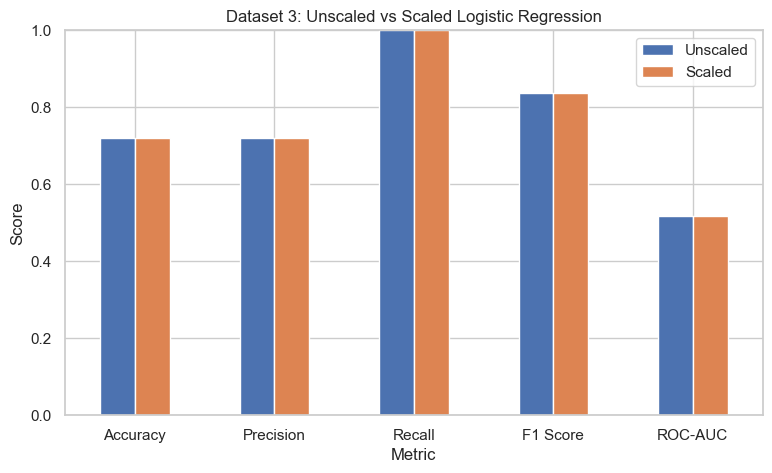

In [26]:
comparison3 = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "Unscaled": [accuracy_score(y3_test, pred3), precision_score(y3_test, pred3), recall_score(y3_test, pred3), f1_score(y3_test, pred3), roc_auc_score(y3_test, prob3)],
    "Scaled": [accuracy_score(y3_test, scaled_pred3), precision_score(y3_test, scaled_pred3), recall_score(y3_test, scaled_pred3), f1_score(y3_test, scaled_pred3), roc_auc_score(y3_test, scaled_prob3)]
})

comparison3.set_index("Metric").plot(kind="bar", figsize=(9, 5))
plt.ylabel("Score")
plt.title("Dataset 3: Unscaled vs Scaled Logistic Regression")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

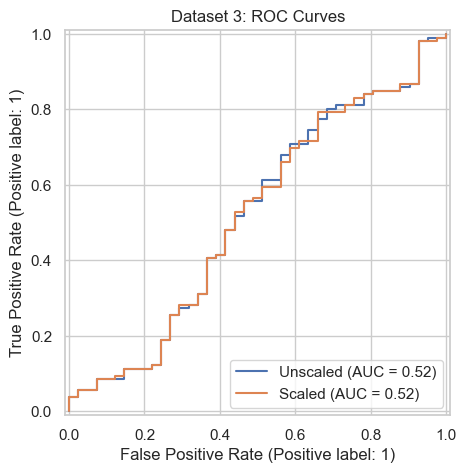

In [27]:
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(y3_test, prob3, name="Unscaled", ax=ax)
RocCurveDisplay.from_predictions(y3_test, scaled_prob3, name="Scaled", ax=ax)
plt.title("Dataset 3: ROC Curves")
plt.show()

### Training vs. Testing Performance

Training and holdout testing performance were compared to evaluate potential overfitting. Accuracy, F1 score, and ROC-AUC were used to assess how consistently the logistic regression model performed on unseen data.

     Metric  Training  Testing
0  Accuracy    0.7189   0.7211
1  F1 Score    0.8365   0.8379
2   ROC-AUC    0.5279   0.5177


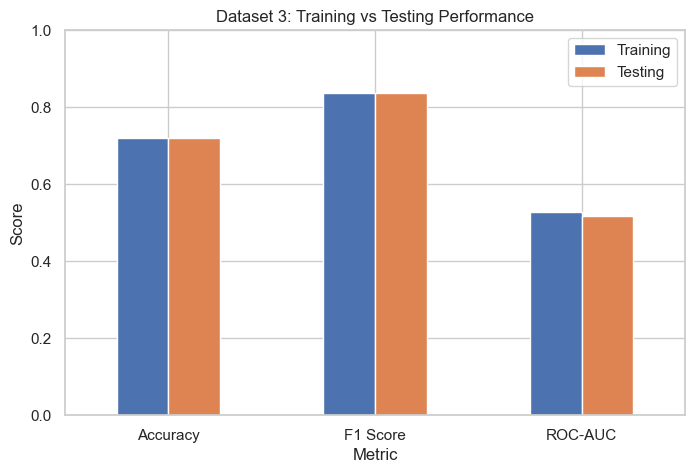

In [38]:
train_pred3 = scaled_logistic3.predict(X3_train)
train_prob3 = scaled_logistic3.predict_proba(X3_train)[:, 1]

performance3 = pd.DataFrame({
    "Metric": ["Accuracy", "F1 Score", "ROC-AUC"],
    "Training": [accuracy_score(y3_train, train_pred3), f1_score(y3_train, train_pred3), roc_auc_score(y3_train, train_prob3)],
    "Testing": [accuracy_score(y3_test, scaled_pred3), f1_score(y3_test, scaled_pred3), roc_auc_score(y3_test, scaled_prob3)]
})

print(performance3.round(4))

performance3.set_index("Metric").plot(kind="bar", figsize=(8, 5))
plt.ylabel("Score")
plt.title("Dataset 3: Training vs Testing Performance")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

The scaled logistic regression model produced similar training and testing results. Training accuracy was 71.89%, compared with 72.11% on the testing set. The F1 scores were also nearly identical at 0.8365 and 0.8379. ROC-AUC decreased slightly from 0.5279 during training to 0.5177 during testing. These results suggest little evidence of overfitting. However, the model's performance remains limited by its tendency to predict the majority Active class.

### Hyperparameter Optimization

GridSearchCV was performed using five folds for cross-validation on the logistic regression model. Regularization parameter values and different class weights were varied to see if tuning can improve classification accuracy. ROC-AUC scoring was chosen for optimization due to the dominance of the Active class in the data set. Holdout testing set was kept aside for testing the optimized model.

In [ ]:
param_grid3 = {
    "logistic__C": [0.01, 0.1, 1, 10, 100],
    "logistic__class_weight": [None, "balanced"]
}

grid3 = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("logistic", LogisticRegression(max_iter=1000))]),
    param_grid3, cv=5, scoring="roc_auc", n_jobs=-1
)
grid3.fit(X3_train, y3_train)

print("Best Parameters:", grid3.best_params_)
print("Best Cross-Validation ROC-AUC:", round(grid3.best_score_, 4))

Best Parameters: {'logistic__C': 0.01, 'logistic__class_weight': None}
Best Cross-Validation ROC-AUC: 0.4841


GridSearchCV, the optimal regularization parameter is C = 0.01 without using balanced class weights. The optimized model was able to obtain a ROC-AUC value of 0.4841 via five-fold cross-validation. This shows that the hyperparameter tuning process was unable to produce a model capable of having a good level of classification performance. The optimized model would then be tested using the testing data set.

In [41]:
tuned_logistic3 = grid3.best_estimator_
tuned_pred3 = tuned_logistic3.predict(X3_test)
tuned_prob3 = tuned_logistic3.predict_proba(X3_test)[:, 1]

print("Accuracy:", round(accuracy_score(y3_test, tuned_pred3), 4))
print("Precision:", round(precision_score(y3_test, tuned_pred3), 4))
print("Recall:", round(recall_score(y3_test, tuned_pred3), 4))
print("F1 Score:", round(f1_score(y3_test, tuned_pred3), 4))
print("ROC-AUC:", round(roc_auc_score(y3_test, tuned_prob3), 4))

Accuracy: 0.7211
Precision: 0.7211
Recall: 1.0
F1 Score: 0.8379
ROC-AUC: 0.5018


For the tuned logistic regression model, the accuracy is 72.11%, precision is 72.11%, recall is 100%, and F1 Score is 0.8379. In addition, ROC-AUC value dropped from 0.5177 to 0.5018. Hyperparameter tuning did not help improve the classification result. The model still classifies each observation into Active. Hence, the chosen variables do not have much power to differentiate between classes.

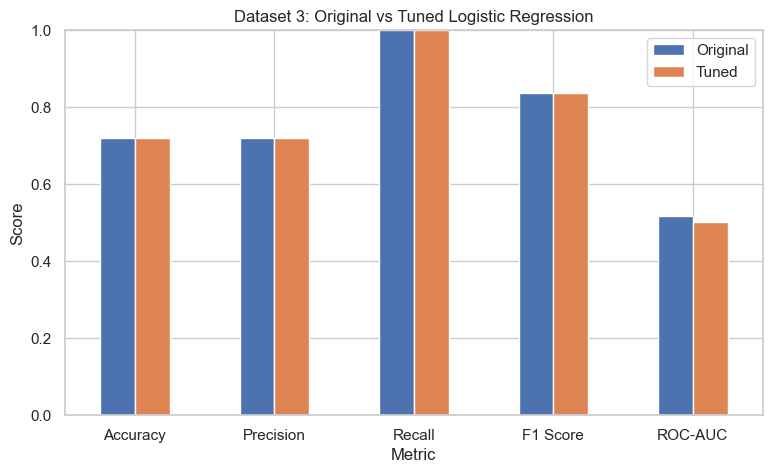

In [42]:
comparison_tuned3 = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "Original": [accuracy_score(y3_test, scaled_pred3), precision_score(y3_test, scaled_pred3), recall_score(y3_test, scaled_pred3), f1_score(y3_test, scaled_pred3), roc_auc_score(y3_test, scaled_prob3)],
    "Tuned": [accuracy_score(y3_test, tuned_pred3), precision_score(y3_test, tuned_pred3), recall_score(y3_test, tuned_pred3), f1_score(y3_test, tuned_pred3), roc_auc_score(y3_test, tuned_prob3)]
})

comparison_tuned3.set_index("Metric").plot(kind="bar", figsize=(9, 5))
plt.ylabel("Score")
plt.title("Dataset 3: Original vs Tuned Logistic Regression")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

### Dataset 3 Conclusion

The logistic regression algorithm gave a testing accuracy of 72.11% on predicting active contracts. From the confusion matrix, it was evident that all the observations were classified as Active with no detection of Not Active contracts by the model. Feature scaling provided very similar results. Performance on training and testing data sets was quite comparable, implying lack of evidence of overfitting in this case. Hyperparameter tuning by GridSearchCV resulted in selection of parameter C = 0.01 without balanced class weights for which the cross-validation ROC-AUC score obtained was 0.4841. On performing hyperparameter tuning, testing accuracy remained the same at 72.11% whereas ROC-AUC score fell from 0.5177 to 0.5018.

## Conclusion
Logistic regression and feature scaling were applied to all three datasets to evaluate classification performance. Dataset 1 achieved the strongest ROC-AUC at approximately 0.70, suggesting some ability to distinguish between conversions and non-conversions. However, its high accuracy was influenced by class imbalance. Dataset 2 performed close to chance level when predicting high- and low-ROI campaigns, while Dataset 3 struggled to identify contracts that were not active. Training and holdout testing comparisons showed relatively small performance differences across all three datasets, suggesting little evidence of substantial overfitting. However, similar training and testing results did not necessarily indicate strong predictive performance, particularly for Datasets 2 and 3. Hyperparameter optimization was performed using GridSearchCV with five-fold cross-validation. Dataset 1 showed the most meaningful change, with balanced class weights improving the identification of non-conversions from 2 to 124 out of 198 observations. However, this improvement reduced overall accuracy and conversion recall. Datasets 2 and 3 showed little to no improvement following tuning. Overall, feature scaling had minimal impact on model performance, while hyperparameter tuning demonstrated that adjusting model settings can change classification behavior without necessarily improving overall predictive ability. These findings highlight the importance of evaluating class imbalance, training and testing performance, and multiple classification metrics when assessing logistic regression models.